# Extracting MBES soundings with knightswhosaydb

The knightswhosaydb package contains some lower level functionality for reading sounding data from raw multibeam echosounder (MBES) files. This can be useful where users would like to treat soundings as point data for spatial mapping applications, or for users who would like to develop their own backscatter processing methods. These tools rely on [themachinethatgoesping](https://github.com/themachinethatgoesping) for reading MBES datagrams.

Currently supported data formats are listed on the [repository page](https://github.com/benjaminmisiuk/knightswhosaydb).

### Reading KMALL files
Here we will read sounding data from raw KMALL files. The first step is to index the KMALL files we would like to process. This is done with [themachinethatgoesping](https://github.com/themachinethatgoesping).

In [13]:
import themachinethatgoesping as theping

files, index = theping.echosounders.index_functions.find_files_and_index('../../data', ['.kmall'])
print(files)

Found 2 files
['../../data\\0008_20250602_161216_Cartwright.kmall', '../../data\\0009_20250602_162948_Cartwright.kmall']


Having indexed these files, we can now read the soundings from the datagrams. We will focus on just one file now for simplicity. This is accomplished by supplying the file and index to the ```read_kmall()``` function.

In [19]:
from knightswhosaydb import read_kmall
f = read_kmall(files[0], index)
f.head()

,ping_no,swath_no,beam_no,east,north,depth,back,beam_angle,angle,azimuth,frequency
0,0.0,0.0,0.0,339568.837611,5.252098e+06,26.870626,-23.614044,57.959621,-59.809566,98.102509,400000.0
1,0.0,0.0,1.0,339568.587649,5.252098e+06,26.824289,-24.915522,57.861771,-59.713013,98.103210,400000.0
2,0.0,0.0,2.0,339568.458560,5.252098e+06,26.849554,-22.519119,57.763348,-59.615540,98.103882,400000.0
3,0.0,0.0,3.0,339568.321120,5.252098e+06,26.870045,-17.220867,57.664337,-59.517502,98.104553,400000.0
4,0.0,0.0,4.0,339568.217067,5.252098e+06,26.910738,-21.786484,57.564739,-59.418770,98.105255,400000.0


We can see that a range of information is available related to the ping, geometry, backscatter, and frequency of the soundings. The output is a pandas dataframe, which can be used for further analysis or exported to a GIS format for mapping.

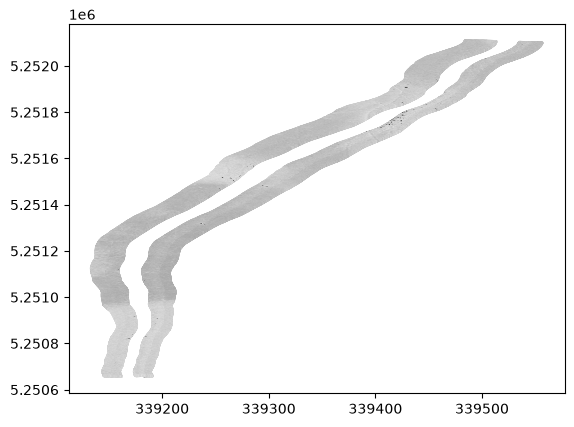

In [39]:
import matplotlib.pyplot as plt

#extract and plot 400 kHz soundings between 20-50 degrees
bs_paradise = f[(f['frequency'] == 400000) & (abs(f['angle']) > 20) & (abs(f['angle']) < 50)]
plt.scatter(bs_paradise['east'], bs_paradise['north'], c=bs_paradise['back'], s=1, cmap='gray')

At this point, we could apply an [AVG function](https://github.com/benjaminmisiuk/knightswhosaydb/blob/main/src/knightswhosaydb/avg_func.py) if we wanted to produce a backscatter mosaic, or we could export the data as a CSV or GIS shapefile.

We can also write a loop to first extract soundings from all KMALL files and bind them together as a single dataframe.

In [46]:
import pandas as pd

#create a list from raw files
lines = list()
for k, file_k in enumerate(files):
    f = read_kmall(file_k, index)
    lines.append(f)

#bind dataframes together from the list
soundings = pd.concat(lines, ignore_index=True)
soundings.head()

,ping_no,swath_no,beam_no,east,north,depth,back,beam_angle,angle,azimuth,frequency
0,0.0,0.0,0.0,339568.837611,5.252098e+06,26.870626,-23.614044,57.959621,-59.809566,98.102509,400000.0
1,0.0,0.0,1.0,339568.587649,5.252098e+06,26.824289,-24.915522,57.861771,-59.713013,98.103210,400000.0
2,0.0,0.0,2.0,339568.458560,5.252098e+06,26.849554,-22.519119,57.763348,-59.615540,98.103882,400000.0
3,0.0,0.0,3.0,339568.321120,5.252098e+06,26.870045,-17.220867,57.664337,-59.517502,98.104553,400000.0
4,0.0,0.0,4.0,339568.217067,5.252098e+06,26.910738,-21.786484,57.564739,-59.418770,98.105255,400000.0


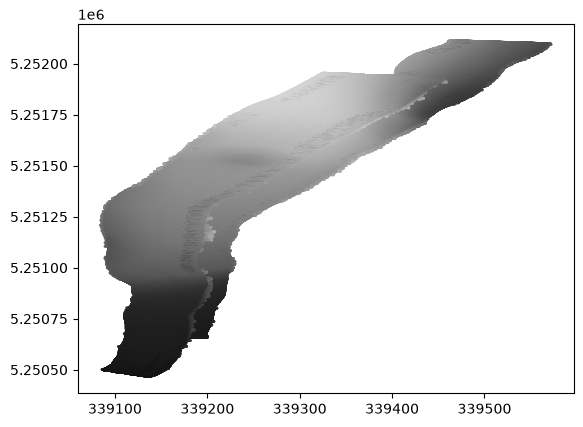

In [47]:
#plot all depth soundings
plt.scatter(soundings['east'], soundings['north'], c=soundings['depth'], s=1, cmap='gray')

Another reason reading the soundings directly can be useful is to change the way that the data are filtered and/or change how AVG is performed. For example, here we could choose to exclude soundings outside of a certain angle, backscatter, and frequency range. We can treat the two survey lines above as a single line for the purposes of processing.

First we filter the dataframe for the soundings of interest.

In [48]:
#select specific soundings
sounding_select = soundings[
    (soundings['frequency'] == 400000) &
    (abs(soundings['angle']) > 10) &
    (abs(soundings['angle']) < 60) &
    (soundings['back'] > -70) &
    (soundings['back'] < 0)
]

Next we can use the [AVG function](https://github.com/benjaminmisiuk/knightswhosaydb/blob/main/src/knightswhosaydb/avg_func.py) provided within the knightswhosaydb package to perform angle-varying gain on the filtered soundings. The ```read_kmall()``` function used above outputs data in a format that can be used directly with the AVG function.

In [56]:
from knightswhosaydb.avg_func import compute_avg

sounding_avg = compute_avg(sounding_select, apply_avg=True)
sounding_avg.head()

,ping_no,swath_no,beam_no,east,north,depth,back,beam_angle,angle,azimuth,...,a_30,a_35,a_40,a_45,a_50,a_55,a_60,a_65,a_70,back_avg
0,0.0,0.0,0.0,339568.837611,5.252098e+06,26.870626,-23.614044,57.959621,-59.809566,98.102509,...,-20.854494,-21.191824,-20.615109,-20.959399,-21.135622,-20.061201,NaN,NaN,NaN,-21.011949
1,0.0,0.0,1.0,339568.587649,5.252098e+06,26.824289,-24.915522,57.861771,-59.713013,98.103210,...,-20.854494,-21.191824,-20.615109,-20.959399,-21.135622,-20.061201,NaN,NaN,NaN,-22.313426
2,0.0,0.0,2.0,339568.458560,5.252098e+06,26.849554,-22.519119,57.763348,-59.615540,98.103882,...,-20.854494,-21.191824,-20.615109,-20.959399,-21.135622,-20.061201,NaN,NaN,NaN,-19.917024
3,0.0,0.0,3.0,339568.321120,5.252098e+06,26.870045,-17.220867,57.664337,-59.517502,98.104553,...,-20.854494,-21.191824,-20.615109,-20.959399,-21.135622,-20.061201,NaN,NaN,NaN,-14.618772
4,0.0,0.0,4.0,339568.217067,5.252098e+06,26.910738,-21.786484,57.564739,-59.418770,98.105255,...,-20.854494,-21.191824,-20.615109,-20.959399,-21.135622,-20.061201,NaN,NaN,NaN,-19.184388


We can compare the soundings before and after filtering and AVG.

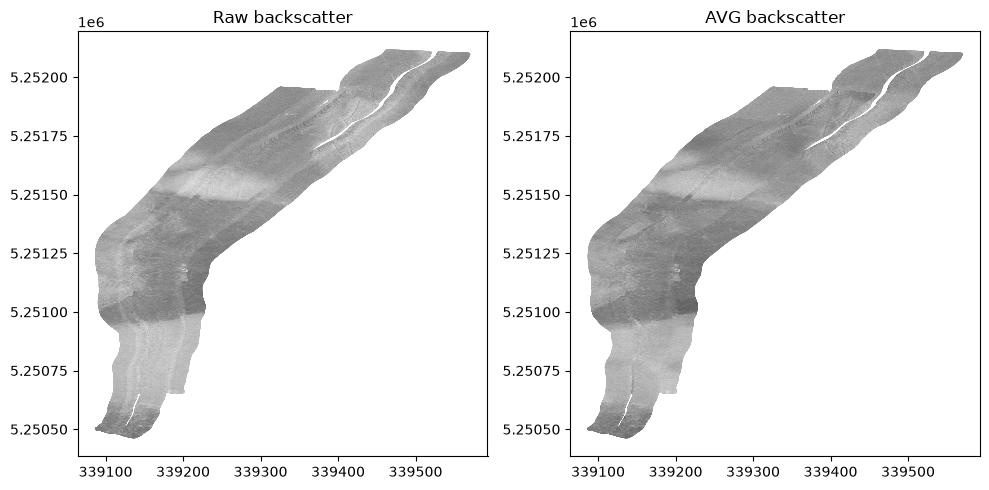

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.scatter(sounding_select['east'], sounding_select['north'], c=sounding_select['back'], s=1, cmap='gray')
ax1.set_title("Raw backscatter")
ax2.scatter(sounding_avg['east'], sounding_avg['north'], c=sounding_avg['back_avg'], s=1, cmap='gray')
ax2.set_title("AVG backscatter")

plt.tight_layout()
plt.show()